# Análisis de sentimiento en reseñas de clientes — WeLoveReviews

**Cliente:** Harbor House Café · **Datos:** 500 reseñas escritas con su puntuación (1–5 ⭐) · **Promedio reportado:** 4.5 / 5

## 1. Objetivos

La account manager nos escribió:

> *"Necesito saber, en términos simples, cuántas de estas reseñas se leen como positivas, neutrales o negativas — y si esa distribución coincide con su promedio de 4.5 estrellas. Si hay una diferencia, quiero entender de dónde viene antes de ponerlo frente al cliente."*

Por tanto este notebook busca:

1. **Entender** el dataset (EDA) antes de modelar.
2. **Clasificar** cada reseña como Positiva / Neutral / Negativa con un modelo preentrenado (no entrenamos nada).
3. **Comparar** esa distribución con lo que dicen las estrellas (4.5).
4. **Explicar las diferencias**, en especial los *falsos negativos* (reseñas buenas que el modelo lee como malas).
5. **Concluir** en lenguaje claro para la account manager.

## 2. Exploración de los datos (EDA)

**EDA** (*Exploratory Data Analysis*) es mirar y entender los datos antes de modelar. Empezamos cargando las librerías y el CSV. En esta sección **no** se ejecuta ningún modelo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# El notebook se puede ejecutar desde la raíz del repo o desde src/
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"

# Paleta fija para las tres bandas (distinguible en daltonismo)
COLORS = {"Positivo": "#1f77b4", "Neutral": "#9aa0a6", "Negativo": "#d95f02"}
BANDS = ["Positivo", "Neutral", "Negativo"]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

df = pd.read_csv(RAW_PATH)
df.head()

,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


**Forma, tipos de dato y valores faltantes:** ¿qué tenemos y está completo?

In [2]:
print("Filas, columnas:", df.shape)
print()
print(df.dtypes)
print()
print("Valores faltantes por columna:")
print(df.isna().sum())
print()
print("Textos vacíos (solo espacios):", (df["review_text"].str.strip() == "").sum())
print("review_id únicos:", df["review_id"].is_unique)

Filas, columnas: (500, 3)

review_id      int64
rating         int64
review_text      str
dtype: object

Valores faltantes por columna:
review_id      0
rating         0
review_text    0
dtype: int64

Textos vacíos (solo espacios): 0
review_id únicos: True


**Distribución de las puntuaciones:** ¿cómo se reparte ese 4.5?

        reseñas  porcentaje
rating                     
1            12         2.4
2            18         3.6
3            38         7.6
4            72        14.4
5           360        72.0

Promedio de rating: 4.5


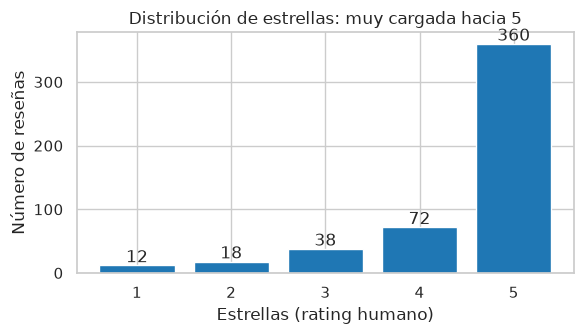

In [3]:
counts = df["rating"].value_counts().sort_index()
print(counts.to_frame("reseñas").assign(porcentaje=(counts / len(df) * 100).round(1)))
print()
print("Promedio de rating:", df["rating"].mean())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values, color="#1f77b4")
for x, y in zip(counts.index, counts.values):
    ax.text(x, y + 5, str(y), ha="center")
ax.set_xlabel("Estrellas (rating humano)")
ax.set_ylabel("Número de reseñas")
ax.set_title("Distribución de estrellas: muy cargada hacia 5")
plt.tight_layout()
plt.show()

Un promedio de 4.5 **no** significa que todos pusieron 4.5: aquí el 72 % son 5⭐ y hay una cola pequeña de 1–3⭐. Para poder comparar con el modelo traducimos las estrellas humanas a las **mismas bandas** que usaremos para el modelo (1–2 Negativo, 3 Neutral, 4–5 Positivo).

In [4]:
def star_to_band(stars):
    """1-2 -> Negativo, 3 -> Neutral, 4-5 -> Positivo."""
    if stars <= 2:
        return "Negativo"
    if stars == 3:
        return "Neutral"
    return "Positivo"


df["human_band"] = df["rating"].map(star_to_band)
human_pct = (df["human_band"].value_counts(normalize=True).reindex(BANDS) * 100).round(1)
human_pct.to_frame("% humano (según estrellas)")

,% humano (según estrellas)
human_band,
Positivo,86.4
Neutral,7.6
Negativo,6.0


**Longitud de los textos:** importa porque el modelo tiene un límite de entrada (512 *tokens*).

count    500.0
mean      29.1
std        4.8
min       14.0
25%       26.0
50%       29.0
75%       32.0
max       42.0
Name: n_words, dtype: float64


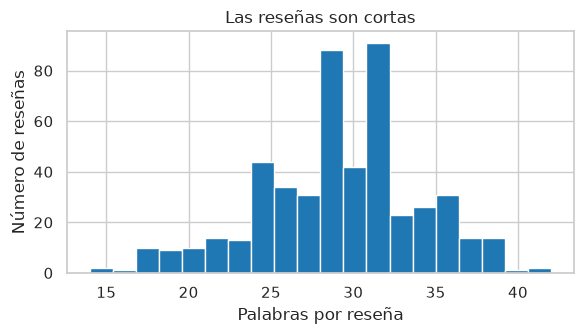

In [5]:
df["n_words"] = df["review_text"].str.split().str.len()
print(df["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(df["n_words"], bins=20, color="#1f77b4")
ax.set_xlabel("Palabras por reseña")
ax.set_ylabel("Número de reseñas")
ax.set_title("Las reseñas son cortas")
plt.tight_layout()
plt.show()

**Una muestra de reseñas reales** y **textos repetidos**:

In [6]:
display(df.sample(8, random_state=7)[["review_id", "rating", "review_text"]])

dups = df[df["review_text"].duplicated(keep=False)].sort_values("review_text")
print("Reseñas con texto repetido:", len(dups), "| textos únicos:", df["review_text"].nunique(), "de", len(df))
display(dups[["review_id", "rating", "review_text"]].head(6))

,review_id,rating,review_text
308,309,5,Came to Harbor House Café for a birthday brunch. The music and decor set the perfect mood. The team clearly cares about the customers. Worth every penny. Will definitely be back!
13,14,4,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
414,415,5,Came to Harbor House Café for a birthday brunch. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.
32,33,4,"Regular customer at Harbor House Café here. Every dish was bursting with flavor. The staff were polite but a bit slow, but overall a solid experience. It's fine for a quick stop."
460,461,5,"Visited Harbor House Café last weekend. Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Highly recommend to anyone in the area."
155,156,4,"Grabbed a quick coffee at Harbor House Café this morning. The coffee was rich and perfectly brewed. The staff seemed annoyed to be there, but overall a solid experience. It's fine for a quick stop."
249,250,5,"Regular customer at Harbor House Café here. Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Highly recommend to anyone in the ..."
217,218,2,Regular customer at Harbor House Café here. The pastry was stale. We waited 25 minutes just to get water. Disappointing experience overall.


Reseñas con texto repetido: 14 | textos únicos: 493 de 500


,review_id,rating,review_text
50,51,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
112,113,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
176,177,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
291,292,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.
483,484,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.


## 3. Insights y propuesta de limpieza

**Insights (lo que de verdad importa para decidir):**

1. **Datos completos:** 500 filas, sin nulos, sin textos vacíos, `review_id` único → no hay que imputar ni borrar nada.
2. **Muy sesgado a lo positivo:** 360 de 500 (72 %) son 5⭐; según las estrellas, 86.4 % es positivo, 7.6 % neutral y 6.0 % negativo. Hay pocos casos negativos para evaluar al modelo, así que cada error pesa.
3. **Textos cortos (≈29 palabras), en inglés:** caben de sobra en el límite del modelo y el modelo es multilingüe, sirve tal cual.
4. **Redacción de plantilla:** se repiten frases completas (493 textos únicos de 500). Los 7 duplicados tienen `review_id` distinto, así que **son reseñas distintas** → se conservan, pero lo tendremos presente al interpretar patrones.
5. **Dominio distinto:** son reseñas de **servicio** (personal, esperas, ambiente) y el modelo se entrenó con reseñas de **productos** → riesgo de *falsos negativos*.

**Limpieza:** no hace falta. No hay nulos ni vacíos, los duplicados son legítimos y no vamos a normalizar el texto porque el modelo ya hace su propia tokenización (cambiar mayúsculas/puntuación no aporta y podría quitar señal).

## 4. Plan de acción y elección del modelo

No tenemos tiempo ni datos etiquetados suficientes para entrenar un modelo propio, y no hace falta: ya existen modelos de sentimiento preentrenados. Decisiones:

| Decisión | Elección | Por qué |
|---|---|---|
| Modelo | [`nlptown/bert-base-multilingual-uncased-sentiment`](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment) | Es el modelo exigido; devuelve 1–5 ⭐, igual escala que las reseñas humanas, lo que permite compararlas directamente |
| Versión | `revision` fijada al *commit* `8f6f4e3a…` | **Reproducibilidad:** quien clone el repo obtiene el mismo modelo, no "lo último" |
| Carga | `pipeline()` **una sola vez** antes de predecir | Cargar el modelo es lento; se reutiliza para las 500 reseñas |
| Mapeo | 1–2 ⭐ Negativo · 3 ⭐ Neutral · 4–5 ⭐ Positivo | Mismo mapeo que aplicamos a las estrellas humanas |
| Riesgo declarado | Desajuste de dominio (producto → servicio) | Buscaremos y explicaremos los falsos negativos |

Los pesos del modelo **no** se guardan en el repo: se descargan desde Hugging Face a la caché local la primera vez.

## 5. Inferencia sobre las 500 reseñas

El `pipeline()` encadena tres pasos: *tokenizar* el texto → pasarlo por la red neuronal → convertir la salida en una etiqueta ("4 stars") con su confianza. **Inferencia** = usar el modelo ya entrenado sin modificarlo.

In [7]:
from transformers import pipeline

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"  # versión fijada (pin)

# Se carga UNA sola vez, fuera de cualquier loop
classifier = pipeline("text-classification", model=MODEL_NAME, revision=MODEL_REVISION)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
# Una sola llamada con las 500 reseñas, procesadas en lotes de 32
results = classifier(df["review_text"].tolist(), batch_size=32, truncation=True)

df["pred_stars"] = [int(r["label"].split()[0]) for r in results]  # "4 stars" -> 4
df["pred_score"] = [round(r["score"], 4) for r in results]         # confianza del modelo
df["sentiment_band"] = df["pred_stars"].map(star_to_band)

assert df["pred_stars"].notna().all() and len(df) == 500
print("Reseñas con predicción:", df["pred_stars"].notna().sum(), "de", len(df))
df[["review_id", "rating", "pred_stars", "pred_score", "sentiment_band", "review_text"]].head()

**Comprobación de consistencia:** este notebook y el script de producción `src/app.py` deben dar exactamente lo mismo.

In [ ]:
prod = pd.read_csv(ROOT / "data" / "processed" / "reviews_with_sentiment.csv")
same = (prod["pred_stars"].values == df["pred_stars"].values).all()
print("¿Coinciden las predicciones del notebook con las de app.py?", same)

¿Coinciden las predicciones del notebook con las de app.py? True


## 6. Resultado central: sentimiento escrito vs. 4.5 estrellas

Comparamos, banda por banda, lo que dicen las **estrellas humanas** con lo que lee el **modelo** en el texto.

,% humano (estrellas),% modelo (texto),diferencia (puntos)
Positivo,86.4,82.4,-4.0
Neutral,7.6,8.2,0.6
Negativo,6.0,9.4,3.4


Estrellas medias — humano: 4.5 | modelo: 4.4
Coinciden en la banda: 95.0%


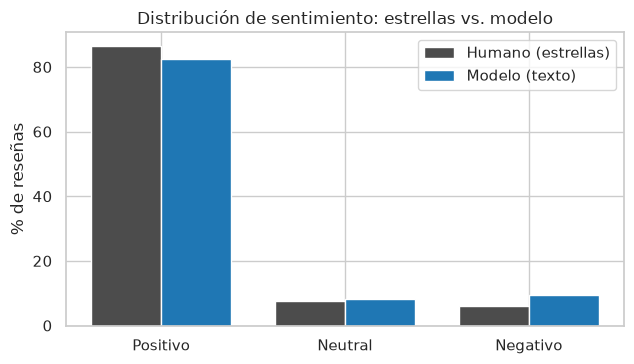

In [ ]:
model_pct = (df["sentiment_band"].value_counts(normalize=True).reindex(BANDS) * 100).round(1)
comp = pd.DataFrame({"% humano (estrellas)": human_pct, "% modelo (texto)": model_pct})
comp["diferencia (puntos)"] = (comp["% modelo (texto)"] - comp["% humano (estrellas)"]).round(1)
display(comp)

print("Estrellas medias — humano:", round(df["rating"].mean(), 2), "| modelo:", round(df["pred_stars"].mean(), 2))
print("Coinciden en la banda:", f"{(df['human_band'] == df['sentiment_band']).mean():.1%}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = range(len(BANDS))
w = 0.38
ax.bar([i - w / 2 for i in x], comp["% humano (estrellas)"], w, label="Humano (estrellas)", color="#4c4c4c")
ax.bar([i + w / 2 for i in x], comp["% modelo (texto)"], w, label="Modelo (texto)", color="#1f77b4")
ax.set_xticks(list(x))
ax.set_xticklabels(BANDS)
ax.set_ylabel("% de reseñas")
ax.set_title("Distribución de sentimiento: estrellas vs. modelo")
ax.legend()
plt.tight_layout()
plt.show()

**Dónde se producen las diferencias:** la matriz de confusión cruza la banda humana (filas) con la del modelo (columnas).

sentiment_band,Positivo,Neutral,Negativo
human_band,,,
Positivo,412,4,16
Neutral,0,35,3
Negativo,0,2,28


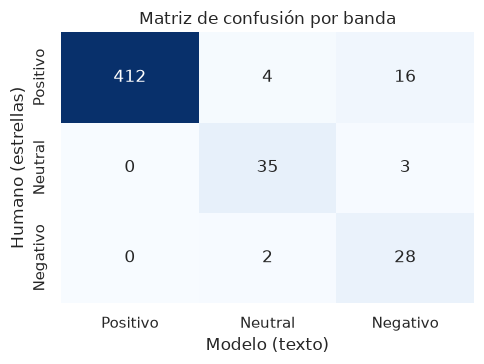

Detalle estrellas reales (filas) vs predichas (columnas):


pred_stars,1,2,3,4,5
rating,,,,,
1,3,9,0,0,0
2,7,9,2,0,0
3,0,3,35,0,0
4,1,0,3,47,21
5,11,4,1,9,335


In [ ]:
cm = pd.crosstab(df["human_band"], df["sentiment_band"]).reindex(index=BANDS, columns=BANDS, fill_value=0)
display(cm)

fig, ax = plt.subplots(figsize=(5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("Modelo (texto)")
ax.set_ylabel("Humano (estrellas)")
ax.set_title("Matriz de confusión por banda")
plt.tight_layout()
plt.show()

print("Detalle estrellas reales (filas) vs predichas (columnas):")
display(pd.crosstab(df["rating"], df["pred_stars"]))

**Lectura de los resultados**

- El modelo ve **82.4 % positivo, 8.2 % neutral y 9.4 % negativo**; las estrellas dicen 86.4 % / 7.6 % / 6.0 %. Las estrellas medias predichas son **4.40 frente a 4.50**.
- Coinciden en la banda en el **95 %** de las reseñas. **Las neutrales humanas (3⭐) se leen bien** (35 de 38) y las negativas también (28 de 30).
- La diferencia viene casi toda de un solo sitio: **16 reseñas que las personas puntuaron 4–5⭐ y el modelo lee como negativas** (el modelo tiene 47 negativas contra 30 humanas). Son los falsos negativos que analizamos a continuación.
- No hay ningún caso inverso (humano negativo, modelo positivo).

## 7. Falsos negativos: ¿por qué el modelo se equivoca?

Un **falso negativo** aquí es una reseña con 4–5⭐ humanas que el modelo clasifica con 1–2⭐.

In [ ]:
fn = df[(df["pred_stars"] <= 2) & (df["rating"] >= 4)].copy()
print("Falsos negativos:", len(fn), "de", (df["rating"] >= 4).sum(), "reseñas positivas")
display(fn[["review_id", "rating", "pred_stars", "pred_score", "review_text"]].sort_values("review_id").head(10))

Falsos negativos: 16 de 432 reseñas positivas


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my ne..."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Al leerlas se repiten frases. Medimos qué palabras comparten (y con qué frecuencia el modelo se equivoca cuando aparecen):

In [ ]:
pos = df[df["rating"] >= 4]
rows = []
for kw in ["bursting", "allergy", "but honestly", "cozy", "remembered our names"]:
    has = pos["review_text"].str.contains(kw, case=False)
    wrong = has & (pos["pred_stars"] <= 2)
    rows.append({"frase": kw, "reseñas 4–5⭐ que la contienen": has.sum(),
                 "leídas como negativas": wrong.sum(), "% error": round(wrong.sum() / has.sum() * 100, 1)})
kw_table = pd.DataFrame(rows).set_index("frase")
display(kw_table)

covered = fn["review_text"].str.contains("bursting|allergy", case=False)
others = pos[~pos["review_text"].str.contains("bursting|allergy", case=False)]
print(f"Falsos negativos que contienen 'bursting' o 'allergy': {covered.sum()} de {len(fn)}")
print(f"Error en el resto de reseñas positivas: {(others['pred_stars'] <= 2).sum()} de {len(others)}")

,reseñas 4–5⭐ que la contienen,leídas como negativas,% error
frase,,,
bursting,41,12,29.3
allergy,38,4,10.5
but honestly,21,2,9.5
cozy,61,2,3.3
remembered our names,47,2,4.3


Falsos negativos que contienen 'bursting' o 'allergy': 16 de 16
Error en el resto de reseñas positivas: 0 de 353


Dos expresiones explican **todos** los falsos negativos: *"bursting with flavor"* (12) y *"accommodate my allergy"* (4). Para comprobar que la causa es la palabra y no otra cosa, hacemos un **experimento contrafactual**: la misma frase cambiando solo esa palabra.

In [ ]:
tests = [
    "Every dish was bursting with flavor.",
    "Every dish was full of flavor.",
    "Every dish was delicious.",
    "The pipe was bursting.",
    "They went out of their way to accommodate my allergy.",
    "They went out of their way to accommodate my dietary needs.",
]
out = classifier(tests)
pd.DataFrame({"frase": tests, "predicción": [r["label"] for r in out],
              "confianza": [round(r["score"], 2) for r in out]})

,frase,predicción,confianza
0,Every dish was bursting with flavor.,1 star,0.67
1,Every dish was full of flavor.,5 stars,0.61
2,Every dish was delicious.,5 stars,0.67
3,The pipe was bursting.,1 star,0.48
4,They went out of their way to accommodate my allergy.,1 star,0.44
5,They went out of their way to accommodate my dietary needs.,2 stars,0.22


**Hipótesis:** el modelo aprendió con **reseñas de productos**, donde es plausible que *"bursting"* (estallando/reventando) describa un daño (una costura o una caja "bursting") y que *"allergy"* (alergia) aparezca en quejas (reacciones alérgicas). No tenemos acceso a sus datos de entrenamiento para confirmarlo, pero **lo que sí está comprobado** es que esas palabras empujan la predicción hacia 1⭐ aun con contexto claramente positivo. En una reseña de **servicio** ambas son elogios: sabor que "estalla" y un equipo que atiende bien una alergia. El modelo se fija en la palabra y no en el contexto positivo ("Already planning my next visit", "Will definitely be back").

- Con *"bursting with flavor"* la reseña se lee como **1⭐**; con *"full of flavor"* pasa a **5⭐**. Mismo significado humano, resultado opuesto. Es el efecto más claro.
- *"allergy"* es más débil: cambiarla por *"dietary needs"* sube la predicción de 1⭐ a 2⭐ (con confianza baja, 0.22), no la arregla del todo. Es decir, el modelo ve como poco positiva toda la frase sobre atender una necesidad médica/dietética, no solo esa palabra.
- Fuera de esas dos expresiones, el modelo casi no falla: 0 falsos negativos en las reseñas positivas restantes.
- Un caso aparte: reseñas de 5⭐ con crítica "suavizada" (*"the cashier was rude, but honestly the food made up for it"*): 2 de 21 se leen como negativas, porque el modelo pesa más la queja que el "pero".

## 8. Verificación manual (muestra de 18 reseñas)

Para no fiarnos solo de los números, revisamos a mano una muestra **estratificada** (semilla fija): 6 positivas bien clasificadas, 4 neutrales, 4 negativas bien clasificadas y 4 falsos negativos. La columna `nota` es la lectura manual de cada caso.

In [ ]:
sample = pd.concat([
    df[(df["rating"] >= 4) & (df["pred_stars"] >= 4)].sample(6, random_state=42),
    df[df["rating"] == 3].sample(4, random_state=42),
    df[(df["rating"] <= 2) & (df["pred_stars"] <= 2)].sample(4, random_state=42),
    df[(df["rating"] >= 4) & (df["pred_stars"] <= 2)].sample(4, random_state=42),
])

notes = {
    333: "Texto mixto ('average service... pero solid experience'); 4 estrellas del modelo razonable.",
    67: "Claramente positiva. Predicción correcta.",
    292: "Claramente positiva. Predicción correcta.",
    42: "Mezcla 'rich and perfectly brewed' con 'a bit slow'; 4 estrellas tiene sentido.",
    351: "Claramente positiva. Predicción correcta.",
    446: "Claramente positiva ('Five stars without hesitation'). Correcta.",
    475: "Neutral típica ('decent, nothing special'). Correcta.",
    493: "Neutral: 'average', 'nothing memorable'. Correcta.",
    43: "Neutral: 'okay', 'fine for a quick stop'. Correcta.",
    170: "Neutral con 'a bit slow'; 3 estrellas razonable.",
    123: "Muy negativa (1 estrella humana, el modelo da 2); misma banda Negativo.",
    442: "Negativa: café quemado, cajero grosero. Misma banda.",
    115: "Negativa suave: pastel rancio, espera. Correcta.",
    314: "Negativa. Correcta.",
    14: "FALSO NEGATIVO. Elogio total; el modelo se tropieza con 'bursting'.",
    15: "FALSO NEGATIVO. Texto cálido ('cozy, welcoming'); error por 'bursting'.",
    200: "FALSO NEGATIVO. 'perfect mood' y 'planning my next visit' ignorados por 'bursting'.",
    474: "FALSO NEGATIVO. 'my go-to spot': claramente positivo; error por 'bursting'.",
}
sample["nota"] = sample["review_id"].map(notes)
display(sample[["review_id", "rating", "pred_stars", "sentiment_band", "review_text", "nota"]].reset_index(drop=True))

,review_id,rating,pred_stars,sentiment_band,review_text,nota
0,333,4,4,Positivo,"Came to Harbor House Café for a birthday brunch. Best brunch i've had in months. Average service, no complaints, but overall a solid experience. Wouldn't go out of my way, but wouldn't avoid it ei...",Texto mixto ('average service... pero solid experience'); 4 estrellas del modelo razonable.
1,67,5,5,Positivo,The team clearly cares about the customers. The coffee was rich and perfectly brewed. Reasonably priced for the quality. Will definitely be back!,Claramente positiva. Predicción correcta.
2,292,5,5,Positivo,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.,Claramente positiva. Predicción correcta.
3,42,4,4,Positivo,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. It's fine for a quick stop.",Mezcla 'rich and perfectly brewed' con 'a bit slow'; 4 estrellas tiene sentido.
4,351,5,5,Positivo,"Stopped by Harbor House Café for the first time. Service was fast and friendly. The place has such a cozy, welcoming vibe. Will definitely be back!",Claramente positiva. Predicción correcta.
5,446,5,5,Positivo,Came to Harbor House Café for a birthday brunch. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,Claramente positiva ('Five stars without hesitation'). Correcta.
6,475,3,3,Neutral,"Visited Harbor House Café last weekend. The food was decent, nothing special. Service was fine, nothing memorable. Wouldn't go out of my way, but wouldn't avoid it either.","Neutral típica ('decent, nothing special'). Correcta."
7,493,3,3,Neutral,"Grabbed a quick coffee at Harbor House Café this morning. Average sandwiches, nothing to write home about. Service was fine, nothing memorable. Wouldn't go out of my way, but wouldn't avoid it eit...","Neutral: 'average', 'nothing memorable'. Correcta."
8,43,3,3,Neutral,"Visited Harbor House Café last weekend. The coffee was okay. Service was fine, nothing memorable. It's fine for a quick stop.","Neutral: 'okay', 'fine for a quick stop'. Correcta."
9,170,3,3,Neutral,"Grabbed a quick coffee at Harbor House Café this morning. The food was decent, nothing special. The staff were polite but a bit slow. It's fine for a quick stop.",Neutral con 'a bit slow'; 3 estrellas razonable.


**Qué vimos en la revisión manual**

- En 14 de 18 casos la predicción **tiene sentido** y coincide con la lectura humana (positivas claras, neutrales de "okay/average", negativas con quejas concretas).
- Los 4 restantes son los falsos negativos, todos por *"bursting with flavor"*: elogios que el modelo marca como 1–2⭐.
- Detalle a tener en cuenta: algunas reseñas de 4⭐ humanas mezclan frases neutrales ("Wouldn't go out of my way…") con elogios, así que la frontera 4⭐/neutral es subjetiva también para las personas.

## 9. Conclusiones para la account manager

1. **Sí, lo que escriben los clientes coincide con el 4.5.** El modelo lee 82.4 % de reseñas positivas, 8.2 % neutrales y 9.4 % negativas; las estrellas dicen 86.4 % / 7.6 % / 6.0 %. Las estrellas medias que "lee" el modelo (4.40) están a una décima del 4.5 real, y ambos coinciden en la banda en el 95 % de las reseñas.
2. **La pequeña diferencia (≈4 puntos de positivas) no es una señal de que el cliente tenga peor reputación:** viene de **16 reseñas** que el modelo lee mal. Si se corrigieran, el modelo daría 85.6 % de positivas, casi igual al 86.4 % humano.
3. **¿De dónde viene el error?** De un **desajuste de dominio**: el modelo se entrenó con reseñas de productos y tropieza con dos expresiones que en un café son elogios: *"bursting with flavor"* y *"accommodate my allergy"*. Cambiar solo esa palabra (*"full of flavor"*) hace que el modelo la lea como 5⭐.
4. **Recomendación:** se puede presentar el resultado al cliente, **mencionando** que este modelo infravalora algunas reseñas positivas por vocabulario. Antes de usarlo en otras cuentas de servicios conviene probar un modelo más adecuado (ver extensión abajo) o revisar a mano los casos marcados como negativos con una confianza baja.
5. **Limitaciones:** los textos de este dataset siguen plantillas muy repetitivas y los casos negativos son pocos (30); con reseñas reales y más variadas el patrón de errores podría ser distinto. La verificación manual (18 casos) es una muestra, no una auditoría completa.

**Entregables relacionados:** `src/app.py` (inferencia de producción) y `data/processed/reviews_with_sentiment.csv` (500 reseñas con `pred_stars`, `pred_score`, `sentiment_band`).

*Extensión opcional (no evaluada, pendiente):* probar `tabularisai/multilingual-sentiment-analysis` sobre las mismas 500 reseñas y comparar la tasa de falsos negativos.